In [20]:
# Standard libraries
import math
import warnings
import itertools

# Data science & Visualization
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.cm as cm
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Scientific & Machine Learning
from scipy import stats
from scipy.optimize import minimize
from sklearn.model_selection import train_test_split

# Personal libraries
import model_database as db
import simulation_core as sim
import fitting_core as fit

# Jupyter Notebook magic commands
%load_ext autoreload
%autoreload 2


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [21]:

# --------------------------------------------------------------------------
# PATH_DATASET uploading 
# --------------------------------------------------------------------------

# first normalization method
PATH_RAW_DATASET = r"C:\Users\marco\Desktop\Tesi + Laurea\.LabWork\Data\Data from Suzanne\fitness_calc_PB_H3B.xlsx"
PATH_LOG_READS_NORMALIZED = r"C:/Users/marco/Desktop/Tesi + Laurea/.LabWork/Results/log_reads_norm.csv"
PATH_LFC = "C:/Users/marco/Desktop/Tesi + Laurea/.LabWork/Results/lfc_results.csv"

# secondth normalization method
path_H = r"C:\Users\marco\Desktop\Tesi + Laurea\.LabWork\Code\4. Data Transformation\normalized_matrix_H.csv"
path_PB = r"C:\Users\marco\Desktop\Tesi + Laurea\.LabWork\Code\4. Data Transformation\normalized_matrix_PB.csv"

# We load the raw file with no changes.
# data_raw will never be modified — it stays as the original reference.
data_raw = pd.read_excel(PATH_RAW_DATASET)
data_reads_norm = pd.read_csv(PATH_LOG_READS_NORMALIZED)
data_lfc = pd.read_csv(PATH_LFC)

data_reads_norm.columns = data_reads_norm.columns.str.replace(
    "output_", "norm_reads_", regex=False
)

data_lfc.drop(columns=["DECOY", "PYT", "ANCHOR"], inplace=True)

data_H_new = pd.read_csv(path_H)
data_PB_new = pd.read_csv(path_PB)

df_unito = pd.merge(data_H_new, data_PB_new, on='seq_id', how='inner')
df_unito.drop('norm_Control_y', axis=1, inplace=True)
df_unito.rename(columns={'norm_Control_x': 'norm_Control'}, inplace=True)
df_unito.columns = df_unito.columns.str.replace(
    "norm_", "new_norm_reads_", regex=False
)

# --------------------------------------------------------------------------
# Data Merging ( unify the datasets)
# --------------------------------------------------------------------------
df_CLR_norm = pd.merge(data_reads_norm, data_lfc, on="seq_id")
df_CLR_norm['seq_id'] = df_CLR_norm['seq_id'].astype(int)
data = pd.merge(data_raw, df_CLR_norm, on="seq_id")
data = pd.merge(data, df_unito, on="seq_id")


# --------------------------------------------------------------------------
# Data Filtering
# --------------------------------------------------------------------------

MIN_READS_THRESHOLD = 20

n_total   = len(data_raw)
mask_ok   = data["Input_counts"] >= MIN_READS_THRESHOLD
n_removed = (~mask_ok).sum()
n_kept    = mask_ok.sum()

data_filtered = data[mask_ok].copy().reset_index(drop=True)
data_filtered['ANCHOR'] = data_filtered['ANCHOR'].astype(str)

# --------------------------------------------------------------------------
# addign the new normalization lfc method 
# --------------------------------------------------------------------------


numeri_pb = [1, 2, 4, 8]

# Costante per evitare log(0) o divisioni per 0 (pseudocount standard = 1)
pseudocount = 1

for num in numeri_pb:
    col_trattata = f'new_norm_reads_PB{num}'
    col_controllo = 'new_norm_reads_Control'
    nuova_colonna = f'new_lfc_PB{num}'
    
    # Calcolo del Log2 Fold Change con pseudocount
    data_filtered[nuova_colonna] = np.log2(
        (data_filtered[col_trattata] + pseudocount) / (data_filtered[col_controllo] + pseudocount)
    )

numeri_h3b = [1, 2, 3, 4, 5]

# Costante per evitare log(0) o divisioni per 0 (pseudocount standard = 1)
pseudocount = 1

for num in numeri_h3b:
    col_trattata = f'new_norm_reads_H{num}'
    col_controllo = 'new_norm_reads_Control'
    nuova_colonna = f'new_lfc_H3B{num}'
    
    # Calcolo del Log2 Fold Change con pseudocount
    data_filtered[nuova_colonna] = np.log2(
        (data_filtered[col_trattata] + pseudocount) / (data_filtered[col_controllo] + pseudocount)
    )

# --------------------------------------------------------------------------
# Adding the BP feature 
# --------------------------------------------------------------------------

def filter_sequence(sequence: str, to_find: str) -> str:
    """Optimizes the input sequence for the SVM finder by removing the final

    section that follows the specified sub-string (e.g., 'CAG').

    Parameters:
        - sequence: str, the string to be cut
        - to_find: str, the sub-string to locate

    Returns:
        - str: The subsetted string, including the 'to_find' sequence at the
        end.
    Raise:
        - ValueError if the to_find string isn't in the sequence
    """
    # Find the index of the last occurrence (searching from right to left)
    idx = sequence.rfind(to_find)

    # If the sub-string is not found, rfind returns -1.
    if idx == -1:
    # In this case, we return the original sequence.
        raise ValueError(f"The string {to_find} is not in {sequence}.")

    # Slice the string to keep everything from the beginning
    # up to the end of 'to_find' (inclusive)
    return sequence[: idx + len(to_find)]

def BP_extractor(data):
    final_str = 'CAG'
    linker = 'GCG'
    strong_pyt = 'UUUUUCUUUUCUUUU'.replace('U', 'T')
    
    suffix_len = len(linker + strong_pyt + final_str)  # 21nt
    
    return data['full_seq'].apply(lambda seq: seq[-(suffix_len+7):-suffix_len])



pattern = 'CAG'

data_filtered['full_seq'] = data_filtered['full_seq'].apply(
    lambda seq: filter_sequence(seq, pattern)
)

data_filtered['BP_extracted'] = BP_extractor(data_filtered)


focus_sub_data = data_filtered[(data_filtered['DECOY'] == 'Decoy 7') & (data_filtered['PYT'] == 'Strong')]
data_filtered['BP_extracted'] = BP_extractor(data_filtered)

focus_sub_data = data_filtered[(data_filtered['DECOY'] == 'Decoy 7') & (data_filtered['PYT'] == 'Strong')]

# 1. Compute mean normalized reads per unique BP — reference condition only
bp_distribution = focus_sub_data.groupby('BP_extracted')['norm_reads_Ctrl'].mean()

# 2. Sort from highest to lowest
bp_ranked = bp_distribution.sort_values(ascending=False)

ranked_values = bp_ranked.values
ranked_categories = bp_ranked.index.tolist()

# 3. Rank-based quartile cuts
total_unique_bps = len(ranked_categories)
cut_strong       = int(total_unique_bps * 0.25)
cut_intermediate = int(total_unique_bps * 0.75)

strong_bp_names       = set(ranked_categories[:cut_strong])
intermediate_bp_names = set(ranked_categories[cut_strong:cut_intermediate])
weak_bp_names         = set(ranked_categories[cut_intermediate:])

# 4. Assign class to the full dataset
conditions = [
    data_filtered['BP_extracted'].isin(strong_bp_names),
    data_filtered['BP_extracted'].isin(intermediate_bp_names),
    data_filtered['BP_extracted'].isin(weak_bp_names)
]
choices = ['BP_Strong', 'BP_Intermediate', 'BP_Weak']

data_filtered['BP_class'] = np.select(conditions, choices, default='Unknown')



# --------------------------------------------------------------------------
# LFC old and new normalization PB
# --------------------------------------------------------------------------
lfc = [col for col in data_filtered.columns if 'lfc' in col]            # old normalization 
lfc_new = [col for col in data_filtered.columns if 'new_lfc_P' in col]    # new normalization 

# --------------------------------------------------------------------------
# LFC for H3B norm
# --------------------------------------------------------------------------
lfc_h3b = [col for col in data_filtered.columns if 'new_lfc_H' in col]            # old normalization 





# --------------------------------------------------------------------------
# Stratification of classes (BP_class x DECOY x PYT) (PladB)
# --------------------------------------------------------------------------

variables = ['BP_class', 'DECOY', 'PYT']
normalized = [col for col in data_filtered.columns if 'norm_reads' in col]

focus_cols = ['seq_id', *variables, *lfc_new,]                          # using new lfc
df_lfc = data_filtered.loc[:, focus_cols]




unique_values = [df_lfc[col].dropna().unique() for col in variables]
combinations_names = list(itertools.product(*unique_values))

stratified_data =  {}
for key_classes, subset in df_lfc.groupby(variables):
    stratified_data[key_classes] = subset.drop(
        columns = variables
    )

# --------------------------------------------------------------------------
# Stratification of classes (BP_class x DECOY x PYT) (H3B)
# --------------------------------------------------------------------------

variables = ['BP_class', 'DECOY', 'PYT']
normalized = [col for col in data_filtered.columns if 'norm_reads' in col]

focus_cols = ['seq_id', *variables, *lfc_h3b,]                          # using h3b
df_lfc = data_filtered.loc[:, focus_cols]




unique_values = [df_lfc[col].dropna().unique() for col in variables]
combinations_names = list(itertools.product(*unique_values))

stratified_data_h3b =  {}
for key_classes, subset in df_lfc.groupby(variables):
    stratified_data_h3b[key_classes] = subset.drop(
        columns = variables
    )



# --------------------------------------------------------------------------
# CONSTANT definition
# --------------------------------------------------------------------------
DRUG_CONCENTRATIONS_raw = [1e-11, 1e-10, 2e-10, 4e-10, 1e-09]
def scale_drug_concentration(drug_linear, 
                             min_real=1e-11, 
                             max_real=1e-9, 
                             min_scaled=0., 
                             max_scaled=100.0):
    """
    Scala la concentrazione lineare del farmaco in un range lineare personalizzato (es. 1-100)
    passando prima per lo spazio logaritmico, per preservare la sensibilità alle basse dosi.
    """
    # 1. Passaggio allo spazio logaritmico (esponenti)
    log_drug = np.log10(drug_linear)
    log_min = np.log10(min_real)  # -11
    log_max = np.log10(max_real)  # -9
    
    # 2. Traslazione e riscalamento lineare dell'esponente nel nuovo range [min_scaled, max_scaled]
    drug_scaled = min_scaled + (log_drug - log_min) * (max_scaled - min_scaled) / (log_max - log_min)
    
    return drug_scaled

DRUG_CONCENTRATIONS = scale_drug_concentration(DRUG_CONCENTRATIONS_raw)

DRUG_CONCENTRATIONS_raw_h3b = [1e-11, 1e-10, 1e-9, 1e-8, 1e-07, 1e-06]
DRUG_CONCENTRATIONS_h3b = scale_drug_concentration(DRUG_CONCENTRATIONS_raw_h3b)

In [22]:
model_4 = 'k3[linear_decrease]__4nodes'

In [23]:
#===========================================================================================
# Plad B
#===========================================================================================

desired_classes = {
    k: v
    for k, v in stratified_data.items()
    if "BP_Intermediate" not in k 
    and "Weak" not in k 
    and "Unknown" not in k 
    and ('Decoy 7' in k or 'Decoy 1' in k)
}
random_class = ('BP_Strong', 'Decoy 1', 'Strong')
sequences_number = desired_classes[random_class].shape[0] * len(desired_classes.keys())
print(f"The analysis will focus on approximatively n = {sequences_number} sequences....")



# List extraction
class_names  = [f"{k[0]}_{k[1]}_PYT_{k[2]}" for k in desired_classes.keys()]
classes_data = list(desired_classes.values())

#===========================================================================================
# H3b
#===========================================================================================
desired_classes_h3b = {
    k: v
    for k, v in stratified_data_h3b.items()
    if "BP_Intermediate" not in k 
    and "Weak" not in k 
    and "Unknown" not in k 
    and ('Decoy 7' in k or 'Decoy 1' in k)
}

random_class_h3b = ('BP_Strong', 'Decoy 1', 'Strong')
sequences_number_h3b = desired_classes_h3b[random_class_h3b].shape[0] * len(desired_classes_h3b.keys())
print(f"The analysis will focus on approximatively n = {sequences_number_h3b} sequences....")

class_names_h3b  = [f"{k[0]}_{k[1]}_PYT_{k[2]}" for k in desired_classes_h3b.keys()]
classes_data_h3b = list(desired_classes_h3b.values())




The analysis will focus on approximatively n = 7860 sequences....
The analysis will focus on approximatively n = 7860 sequences....


# Fixing costants

In [24]:
fixed_params = {'k1': 1., 'k2': 1.}
shared_param_names = ['k_1', 'k_2', 'k3', 'k4','alpha']
n_bootstrap_runs = 150
n_multistart = 40
LOG_BOUNDS = (-5, 5)   

# Bootstrap Fitting (PladB & H3B)

  bootstrap 15/150 completato (ultimo loss=0.3448, success=True)
  bootstrap 30/150 completato (ultimo loss=0.4530, success=True)
  bootstrap 45/150 completato (ultimo loss=0.5220, success=True)
  bootstrap 60/150 completato (ultimo loss=0.3504, success=True)
  bootstrap 75/150 completato (ultimo loss=0.3444, success=True)
  bootstrap 90/150 completato (ultimo loss=0.3402, success=True)
  bootstrap 105/150 completato (ultimo loss=0.3560, success=True)
  bootstrap 120/150 completato (ultimo loss=0.3749, success=True)
  bootstrap 135/150 completato (ultimo loss=0.3504, success=True)
  bootstrap 150/150 completato (ultimo loss=0.5522, success=True)


c:\Users\marco\Desktop\Tesi + Laurea\.LabWork\Code\5. Fitting\fitting_core.py:1352: UserWarning: 1/150 repliche bootstrap non sono convergute (success=False). Valutare se escluderle dal CI.
  warnings.warn(


  bootstrap 15/150 completato (ultimo loss=0.0897, success=True)
  bootstrap 30/150 completato (ultimo loss=0.0941, success=True)
  bootstrap 45/150 completato (ultimo loss=0.1126, success=True)
  bootstrap 60/150 completato (ultimo loss=0.0949, success=True)
  bootstrap 75/150 completato (ultimo loss=0.1149, success=True)
  bootstrap 90/150 completato (ultimo loss=0.0967, success=True)
  bootstrap 105/150 completato (ultimo loss=0.0979, success=True)
  bootstrap 120/150 completato (ultimo loss=0.0929, success=True)
  bootstrap 135/150 completato (ultimo loss=0.0889, success=True)
  bootstrap 150/150 completato (ultimo loss=0.1014, success=True)


c:\Users\marco\Desktop\Tesi + Laurea\.LabWork\Code\5. Fitting\fitting_core.py:1352: UserWarning: 2/150 repliche bootstrap non sono convergute (success=False). Valutare se escluderle dal CI.
  warnings.warn(


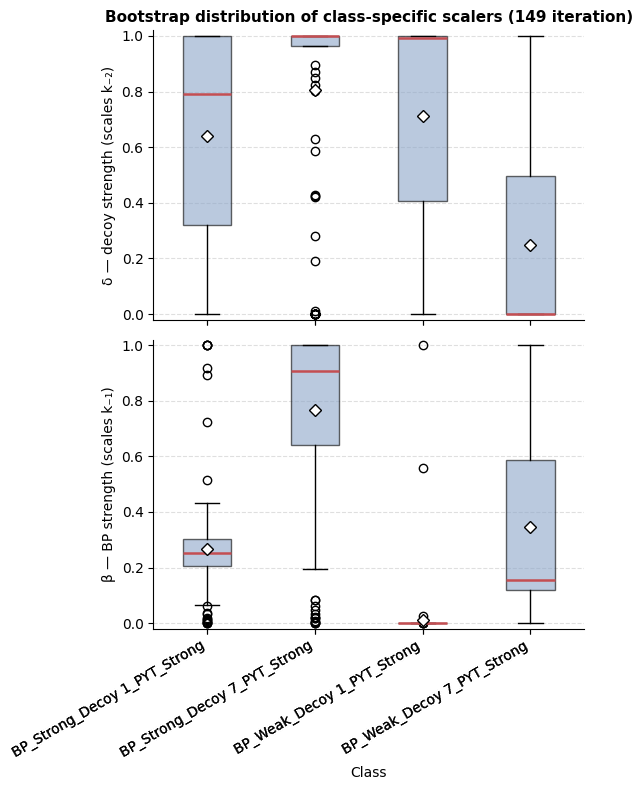

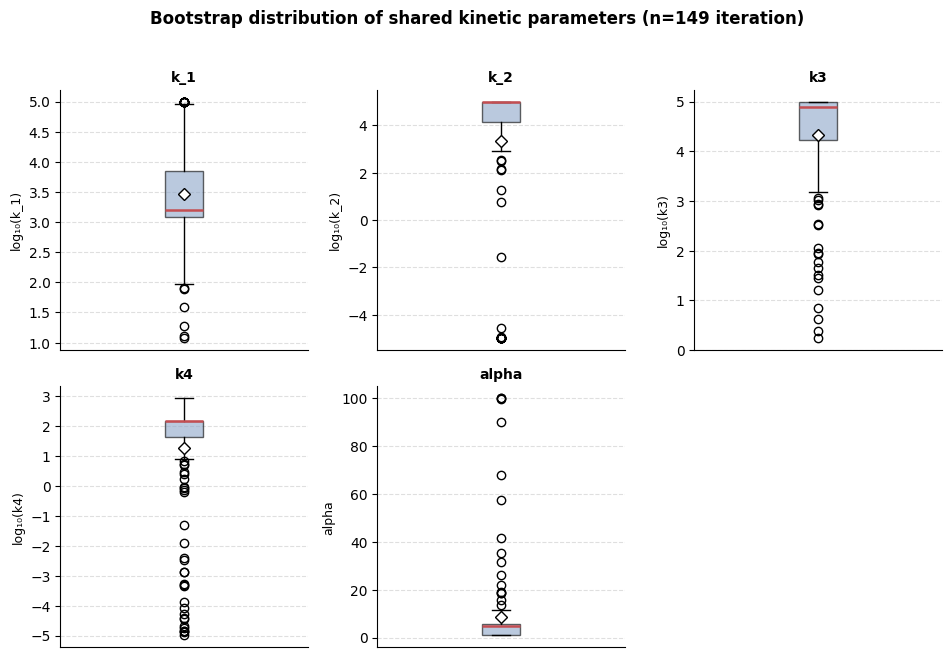

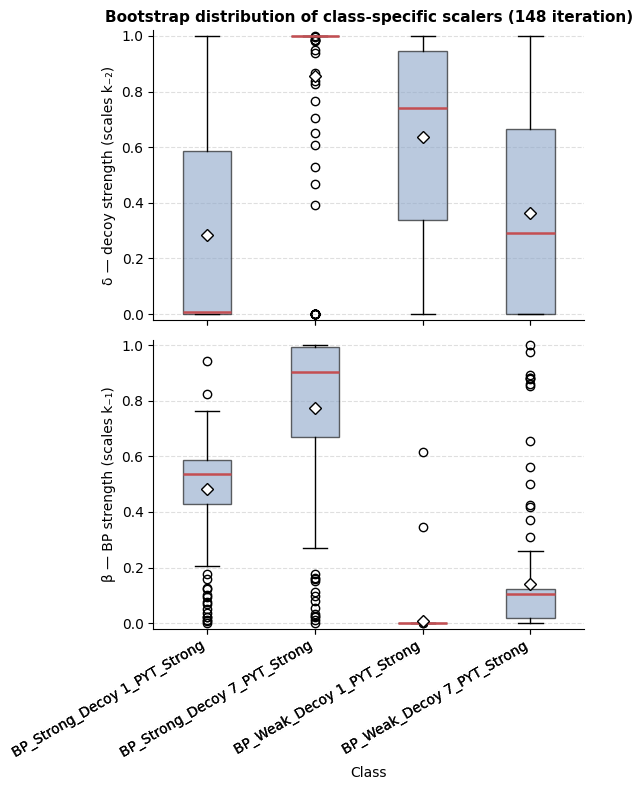

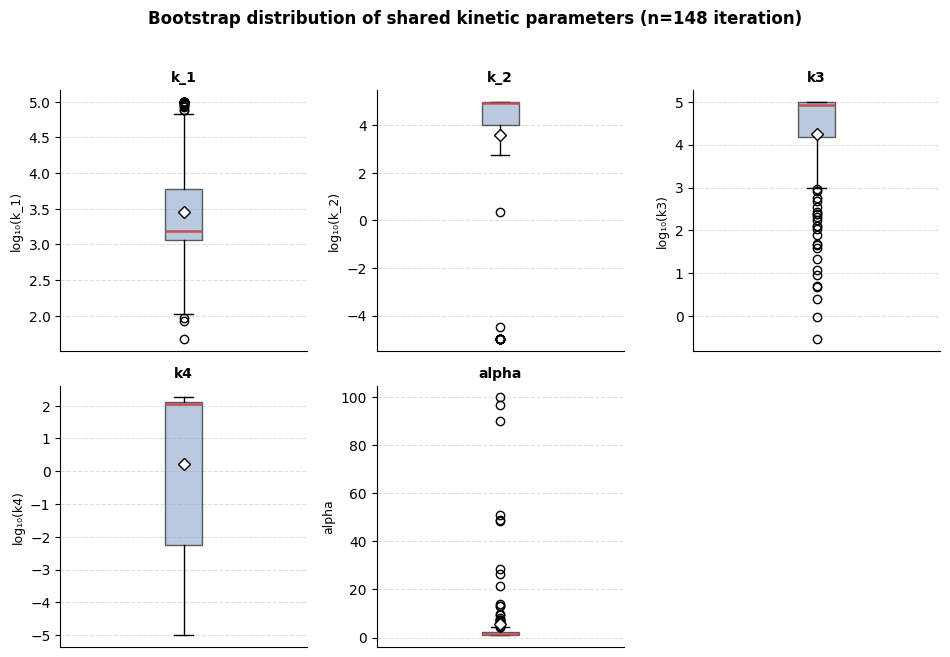

In [25]:
# =============================================================================
# Bootstrap runs
# =============================================================================


df_boot_pb = fit.bootstrap_fit_multiclass(
    classes_data        = classes_data,
    class_names          = class_names,
    shared_param_names   = shared_param_names,
    drug_conc            = DRUG_CONCENTRATIONS,
    model_name            = model_4,
    log_bounds             = LOG_BOUNDS,
    fixed_params            = fixed_params,
    n_bootstrap              = n_bootstrap_runs,
    n_starts_bootstrap        = n_multistart,
    random_seed                 = 1149,
)

df_boot_h3b = fit.bootstrap_fit_multiclass(
    classes_data        = classes_data_h3b,
    class_names          = class_names_h3b,
    shared_param_names   = shared_param_names,
    drug_conc            = DRUG_CONCENTRATIONS_h3b,
    model_name            = model_4,
    log_bounds             = LOG_BOUNDS,
    fixed_params            = fixed_params,
    n_bootstrap              = n_bootstrap_runs,
    n_starts_bootstrap        = n_multistart,
    random_seed                 = 1149,
)

all_params_pb  = shared_param_names + [f'{s}_{c}' for c in class_names for s in ('delta', 'beta')]
all_params_h3b = shared_param_names + [f'{s}_{c}' for c in class_names_h3b for s in ('delta', 'beta')]

ci_table_pb  = fit.summarize_bootstrap_ci(df_boot_pb, all_params_pb, ci=0.95)
ci_table_h3b = fit.summarize_bootstrap_ci(df_boot_h3b, all_params_h3b, ci=0.95)

# Plots
fit.plot_bootstrap_scalers(df_boot_pb, class_names)
fit.plot_bootstrap_shared_params(df_boot_pb, shared_param_names)

fit.plot_bootstrap_scalers(df_boot_h3b, class_names_h3b)
fit.plot_bootstrap_shared_params(df_boot_h3b, shared_param_names)

# PARAMETER COMPARISON PER DRUG

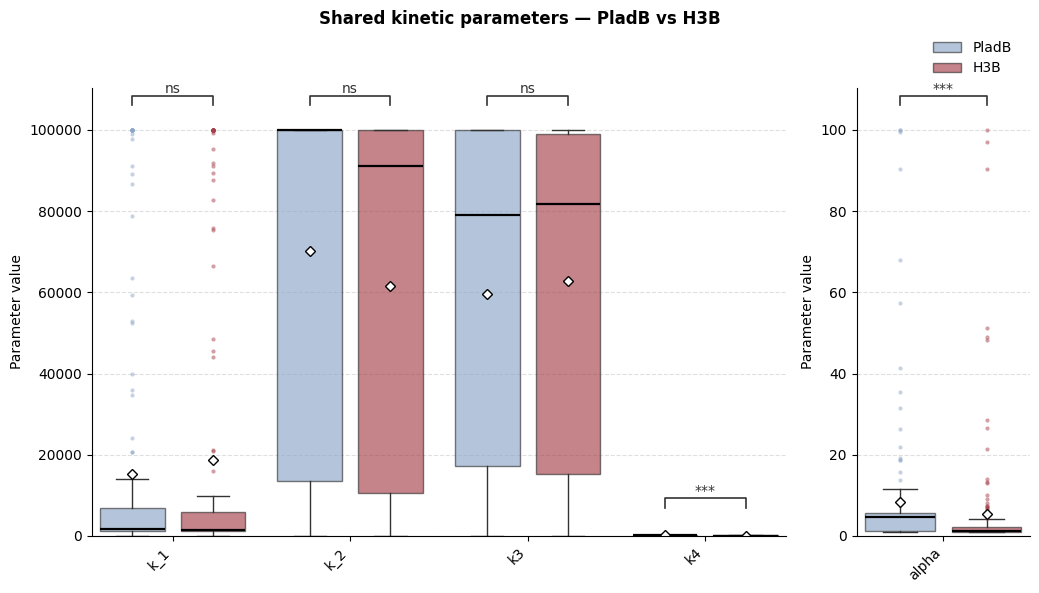

In [93]:
import importlib
importlib.reload(fit)

df_stats_shared = fit.plot_cross_drug_comparison(
    df_pb=df_boot_pb, df_h3b=df_boot_h3b,
    param_names=shared_param_names,
    title='Shared kinetic parameters — PladB vs H3B',
    log_scale=False,
)



# SPECIFC

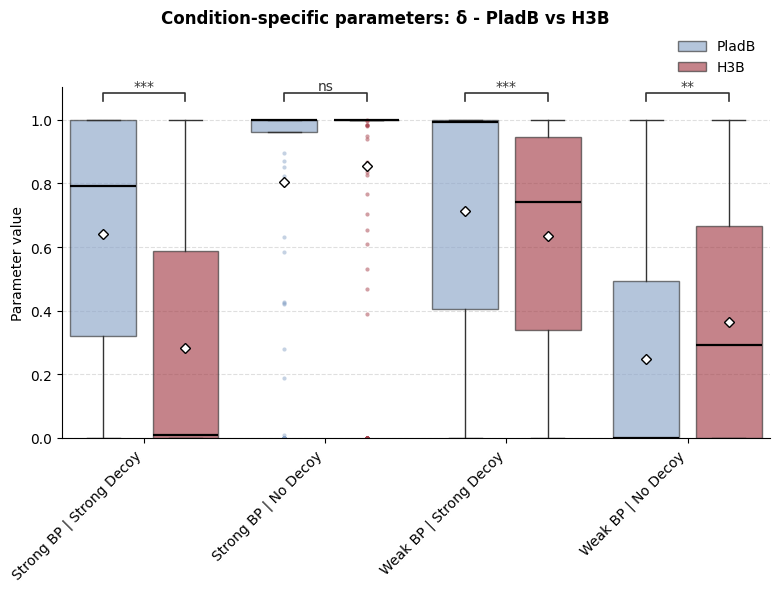

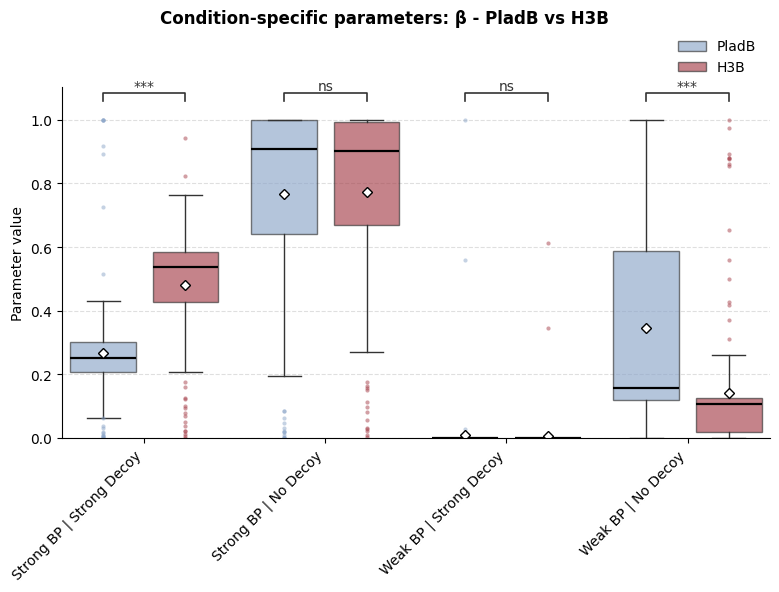

In [96]:
importlib.reload(fit)

df_stats_delta, df_stats_beta = fit.plot_class_specific_comparison_symbolic(
    df_pb=df_boot_pb, df_h3b=df_boot_h3b,
    class_names=class_names,
    class_names_h3b=class_names_h3b,  # None se sono uguali a class_names

y_limits= (0,1))

In [26]:
# =============================================================================
# Parametro "canonico" = mediana bootstrap (usato in Cap.3, Cap.6)
# =============================================================================
def bootstrap_median_dict(df_boot, param_names, only_successful=True):
    """Costruisce il parameter dict 'canonico' come mediana delle repliche bootstrap."""
    data = df_boot[df_boot['success']] if only_successful else df_boot
    return {p: float(data[p].median()) for p in param_names}

best_dict_pb  = bootstrap_median_dict(df_boot_pb, all_params_pb)
best_dict_h3b = bootstrap_median_dict(df_boot_h3b, all_params_h3b)
def bootstrap_canonical_dict(df_boot, all_param_names, only_successful=True):
    """
    Seleziona come parametro 'canonico' la replica bootstrap reale con costo
    (final_cost) più vicino alla mediana — NON la mediana marginale per colonna.
    Preserva le correlazioni tra parametri, che la mediana colonna-per-colonna
    distrugge e che è la causa più probabile degli R^2 poco sensati osservati.
    """
    data = df_boot[df_boot['success']] if only_successful else df_boot
    median_cost = data['final_cost'].median()
    idx_closest = (data['final_cost'] - median_cost).abs().idxmin()
    row = data.loc[idx_closest]
    return {p: float(row[p]) for p in all_param_names}, idx_closest


best_dict_pb,  idx_pb  = bootstrap_canonical_dict(df_boot_pb,  all_params_pb)
best_dict_h3b, idx_h3b = bootstrap_canonical_dict(df_boot_h3b, all_params_h3b)
print(f"PladB: replica #{idx_pb}, cost = {df_boot_pb.loc[idx_pb,'final_cost']:.4f}")
print(f"H3B:   replica #{idx_h3b}, cost = {df_boot_h3b.loc[idx_h3b,'final_cost']:.4f}")

PladB: replica #110, cost = 0.3537
H3B:   replica #21, cost = 0.0956


# Goodness of Fit

In [27]:
def goodness_of_fit_with_rmse(best_dict, shared_param_names, class_names, classes_data,
                                drug_conc, model_name, fixed_params=None):
    gof = fit.goodness_of_fit_multiclass(
        best_dict=best_dict, shared_param_names=shared_param_names,
        class_names=class_names, classes_data=classes_data,
        drug_conc=drug_conc, model_name=model_name, fixed_params=fixed_params,
    )
    rmse_rows = []
    for cname, df in zip(class_names, classes_data):
        obs = fit._observed_lfc(df, drug_conc)
        class_fixed = {'delta': best_dict[f'delta_{cname}'], 'beta': best_dict[f'beta_{cname}']}
        if fixed_params is not None:
            class_fixed = {**fixed_params, **class_fixed}
        shared_values = [best_dict[name] for name in shared_param_names]
        pred = fit._predict_lfc(
            free_parameters_values=shared_values, free_param_names=shared_param_names,
            drug_conc=drug_conc, model_name=model_name, fixed_params=class_fixed,
        )
        rmse = float(np.sqrt(np.mean((obs['means'] - np.asarray(pred)) ** 2)))
        rmse_rows.append({'class': cname, 'rmse': rmse})
    return gof.merge(pd.DataFrame(rmse_rows), on='class', how='left')


gof_rmse_pb  = goodness_of_fit_with_rmse(best_dict_pb,  shared_param_names, class_names,     classes_data,     DRUG_CONCENTRATIONS,     model_4, fixed_params)
gof_rmse_h3b = goodness_of_fit_with_rmse(best_dict_h3b, shared_param_names, class_names_h3b, classes_data_h3b, DRUG_CONCENTRATIONS_h3b, model_4, fixed_params)
print(gof_rmse_pb)
print(gof_rmse_h3b)

                          class        r2  r2_weighted    ss_res     ss_tot  \
0  BP_Strong_Decoy 1_PYT_Strong -0.062339     0.316509  0.338266   0.318416   
1  BP_Strong_Decoy 7_PYT_Strong  0.005354     0.295338  1.388972   1.396450   
2    BP_Weak_Decoy 1_PYT_Strong -0.962190    -0.432264  0.043921   0.022383   
3    BP_Weak_Decoy 7_PYT_Strong -0.072541     0.107128  0.000748   0.000697   
4                       OVERALL  0.841277     0.813607  1.771907  11.163508   

       rmse  
0  0.290803  
1  0.589273  
2  0.104786  
3  0.013675  
4       NaN  
                          class        r2  r2_weighted    ss_res    ss_tot  \
0  BP_Strong_Decoy 1_PYT_Strong  0.137194     0.657644  0.136999  0.158784   
1  BP_Strong_Decoy 7_PYT_Strong  0.418993     0.685925  0.941750  1.620891   
2    BP_Weak_Decoy 1_PYT_Strong  0.343415     0.638788  0.208589  0.317688   
3    BP_Weak_Decoy 7_PYT_Strong  0.259954     0.239212  0.008618  0.011646   
4                       OVERALL  0.855195     0.841

In [108]:
gof_pub_pb = fit.build_publication_gof_table(
    best_dict           = best_dict_pb,
    shared_param_names  = shared_param_names,
    class_names          = class_names,
    classes_data          = classes_data,
    drug_conc              = DRUG_CONCENTRATIONS,
    model_name              = model_4,
    stratified_data          = stratified_data,
    fixed_params              = fixed_params,
)

gof_pub_h3b = fit.build_publication_gof_table(
    best_dict           = best_dict_h3b,
    shared_param_names  = shared_param_names,
    class_names          = class_names_h3b,
    classes_data          = classes_data_h3b,
    drug_conc              = DRUG_CONCENTRATIONS_h3b,
    model_name              = model_4,
    stratified_data          = stratified_data_h3b,
    fixed_params              = fixed_params,
)

print(gof_pub_pb)
print(gof_pub_h3b)

                  Condition Experimental Range  Range Length  RMSE
0  Strong BP | Strong Decoy      [-2.90, 2.05]          4.95  0.29
1      Strong BP | No Decoy      [-3.55, 0.56]          4.11  0.59
2    Weak BP | Strong Decoy      [-1.56, 2.33]          3.89  0.10
3        Weak BP | No Decoy      [-1.24, 0.70]          1.93  0.01
                  Condition Experimental Range  Range Length  RMSE
0  Strong BP | Strong Decoy      [-2.47, 2.37]          4.84  0.17
1      Strong BP | No Decoy      [-3.45, 0.37]          3.82  0.43
2    Weak BP | Strong Decoy      [-1.29, 2.64]          3.93  0.20
3        Weak BP | No Decoy      [-1.22, 1.14]          2.36  0.04


In [112]:
from IPython.display import display, HTML

def show_publication_table(df: pd.DataFrame, title: str = None):
    """Renderizza il dataframe come tabella HTML pulita, pronta per essere
    selezionata col mouse e incollata direttamente in Word (mantiene bordi
    e struttura tabellare)."""

    # Colonne numeriche da formattare a 2 decimali fissi (esclude colonne
    # già testuali come 'Condition' o 'Experimental Range', che è una stringa).
    numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

    styled = (
        df.style
        .hide(axis='index')
        .format(subset=numeric_cols, formatter="{:.2f}")
        .set_table_styles([
            {'selector': 'th', 'props': [('background-color', '#2c3e50'),
                                          ('color', 'white'),
                                          ('padding', '6px 12px'),
                                          ('border', '1px solid #444')]},
            {'selector': 'td', 'props': [('padding', '6px 12px'),
                                          ('border', '1px solid #ccc'),
                                          ('text-align', 'center')]},
            {'selector': 'table', 'props': [('border-collapse', 'collapse')]},
            # Prima colonna (Condition) centrata anche nelle celle dati,
            # non solo nell'header — per default pandas.Styler la allinea
            # a sinistra essendo testo.
            {'selector': 'td:first-child', 'props': [('text-align', 'center')]},
        ])
    )
    if title:
        display(HTML(f"<h4>{title}</h4>"))
    display(styled)

show_publication_table(gof_pub_pb, title="Goodness of Fit — Pladienolide B")
show_publication_table(gof_pub_h3b, title="Goodness of Fit — H3B-8800")

Condition,Experimental Range,Range Length,RMSE
Strong BP | Strong Decoy,"[-2.90, 2.05]",4.95,0.29
Strong BP | No Decoy,"[-3.55, 0.56]",4.11,0.59
Weak BP | Strong Decoy,"[-1.56, 2.33]",3.89,0.10
Weak BP | No Decoy,"[-1.24, 0.70]",1.93,0.01


Condition,Experimental Range,Range Length,RMSE
Strong BP | Strong Decoy,"[-2.47, 2.37]",4.84,0.17
Strong BP | No Decoy,"[-3.45, 0.37]",3.82,0.43
Weak BP | Strong Decoy,"[-1.29, 2.64]",3.93,0.20
Weak BP | No Decoy,"[-1.22, 1.14]",2.36,0.04


# Global fit (inutile tanto li ho gia)

In [28]:
# # plot_fit_comparison_multiclass richiede un oggetto con .fun (per l'etichetta in legenda):
# # uso la mediana del final_cost bootstrap come proxy della loss del parametro canonico.
# class _FitStub:
#     def __init__(self, fun):
#         self.fun = fun

# best_fit_stub_pb  = _FitStub(fun=float(df_boot_pb.loc[df_boot_pb['success'], 'final_cost'].median()))
# best_fit_stub_h3b = _FitStub(fun=float(df_boot_h3b.loc[df_boot_h3b['success'], 'final_cost'].median()))

# fit.plot_fit_comparison_multiclass(
#     classes_data          = classes_data,
#     classes_names          = class_names,
#     best_fit                = best_fit_stub_pb,
#     fit_dict                 = best_dict_pb,
#     drug_conc                 = DRUG_CONCENTRATIONS,
#     real_concentrations        = DRUG_CONCENTRATIONS_raw,
#     model_name                   = model_4,
#     fixed_params                  = fixed_params,
# )

# fit.plot_fit_comparison_multiclass(
#     classes_data          = classes_data_h3b,
#     classes_names          = class_names_h3b,
#     best_fit                = best_fit_stub_h3b,
#     fit_dict                 = best_dict_h3b,
#     drug_conc                 = DRUG_CONCENTRATIONS_h3b,
#     real_concentrations        = DRUG_CONCENTRATIONS_raw_h3b,
#     model_name                   = model_4,
#     fixed_params                  = fixed_params,
# )

# 4.1 Forrest Plot shared parameters

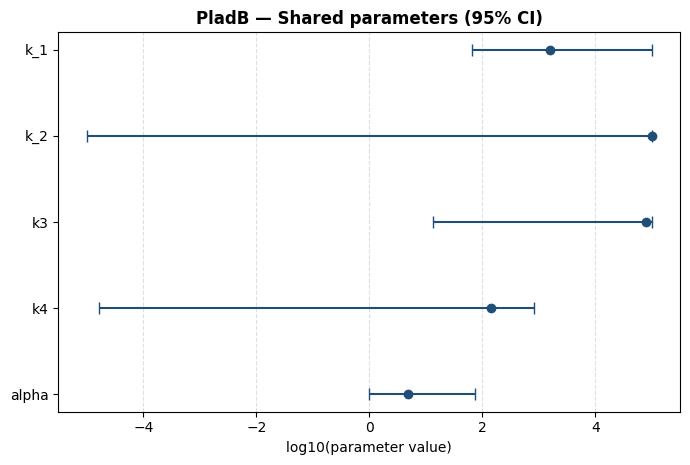

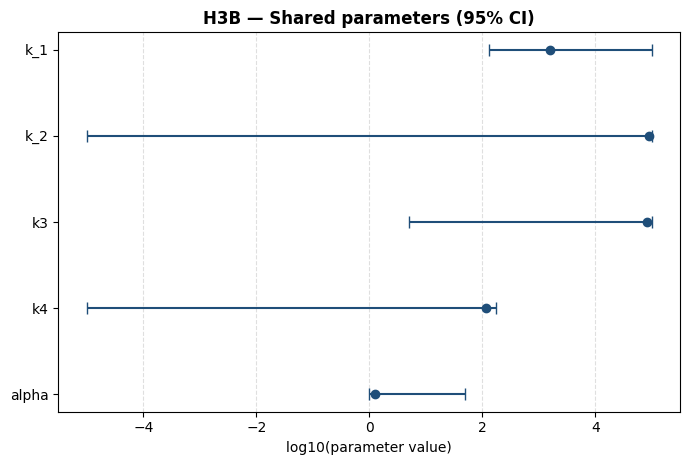

In [29]:
def forest_plot_shared_params(ci_table, log_scale=True, bio_ranges=None,
                                title='Shared kinetic parameters — 95% CI'):
    """
    ci_table: DataFrame con colonne ['param','median','ci_low','ci_high',...]
              (output di fit.summarize_bootstrap_ci)
    bio_ranges: dict opzionale {param_name: (low, high)} per un range biologico
                atteso, disegnato come fascia ombreggiata verde. Lascia None
                se non hai riferimenti di letteratura.
    """
    df = ci_table.reset_index(drop=True)
    y_pos = np.arange(len(df))

    x_med, x_lo, x_hi = df['median'].values, df['ci_low'].values, df['ci_high'].values
    if log_scale:
        x_med_p = np.log10(x_med)
        x_lo_p  = np.log10(np.clip(x_lo, 1e-12, None))
        x_hi_p  = np.log10(np.clip(x_hi, 1e-12, None))
        xlabel = 'log10(parameter value)'
    else:
        x_med_p, x_lo_p, x_hi_p = x_med, x_lo, x_hi
        xlabel = 'parameter value'

    fig, ax = plt.subplots(figsize=(7, 0.55 * len(df) + 2))

    if bio_ranges is not None:
        for i, row in df.iterrows():
            if row['param'] in bio_ranges:
                lo_b, hi_b = bio_ranges[row['param']]
                lo_bp = np.log10(lo_b) if log_scale else lo_b
                hi_bp = np.log10(hi_b) if log_scale else hi_b
                ax.axvspan(lo_bp, hi_bp, ymin=i/len(df), ymax=(i+1)/len(df),
                           color='green', alpha=0.12, zorder=0)

    ax.errorbar(x_med_p, y_pos, xerr=[x_med_p - x_lo_p, x_hi_p - x_med_p],
                fmt='o', color='#1f4e79', ecolor='#1f4e79', capsize=4, markersize=6, zorder=3)

    ax.set_yticks(y_pos)
    ax.set_yticklabels(df['param'])
    ax.set_xlabel(xlabel)
    ax.set_title(title, fontweight='bold')
    ax.grid(True, axis='x', linestyle='--', alpha=0.4)
    ax.invert_yaxis()
    plt.tight_layout()
    plt.show()


ci_shared_pb  = fit.summarize_bootstrap_ci(df_boot_pb, shared_param_names, ci=0.95)
ci_shared_h3b = fit.summarize_bootstrap_ci(df_boot_h3b, shared_param_names, ci=0.95)

# bio_ranges={'k_1': (1e-2, 1e2), ...} se hai valori di letteratura da confrontare
forest_plot_shared_params(ci_shared_pb, log_scale=True, title='PladB — Shared parameters (95% CI)')
forest_plot_shared_params(ci_shared_h3b, log_scale=True, title='H3B — Shared parameters (95% CI)')

# Capitolo 4.2 — Quantificare il problema di identificabilità di delta/beta

fit.plot_bootstrap_scalers(df_boot_pb, class_names) ti dà già il boxplot visivo. Qui aggiungo i due numeri che servono per argomentarlo (non solo mostrarlo):


In [30]:
def scalers_bound_overlap_report(df_boot, class_names, only_successful=True, bound_eps=0.02):
    """Frazione di repliche bootstrap che toccano i bound [0,1] per ciascuno scaler/classe."""
    data = df_boot[df_boot['success']] if only_successful else df_boot
    rows = []
    for scaler in ('delta', 'beta'):
        for c in class_names:
            vals = data[f'{scaler}_{c}'].dropna()
            rows.append({
                'scaler': scaler, 'class': c,
                'median': vals.median(), 'ci_low': vals.quantile(0.025), 'ci_high': vals.quantile(0.975),
                'frac_at_bound': ((vals <= bound_eps) | (vals >= 1 - bound_eps)).mean(),
            })
    return pd.DataFrame(rows)


def scalers_pairwise_overlap(df_boot, class_names, scaler='delta', only_successful=True):
    """% di sovrapposizione dei CI 95% tra tutte le coppie di classi, per uno scaler."""
    data = df_boot[df_boot['success']] if only_successful else df_boot
    ci_by_class = {c: (data[f'{scaler}_{c}'].quantile(0.025), data[f'{scaler}_{c}'].quantile(0.975))
                   for c in class_names}
    rows = []
    for c1, c2 in itertools.combinations(class_names, 2):
        lo1, hi1 = ci_by_class[c1]
        lo2, hi2 = ci_by_class[c2]
        overlap = max(0.0, min(hi1, hi2) - max(lo1, lo2))
        span    = max(hi1, hi2) - min(lo1, lo2)
        rows.append({'class_1': c1, 'class_2': c2,
                      'overlap_pct': 100 * overlap / span if span > 0 else np.nan})
    return pd.DataFrame(rows)


bound_report_pb = scalers_bound_overlap_report(df_boot_pb, class_names)
print(bound_report_pb)

overlap_delta_pb = scalers_pairwise_overlap(df_boot_pb, class_names, scaler='delta')
overlap_beta_pb  = scalers_pairwise_overlap(df_boot_pb, class_names, scaler='beta')
print(overlap_delta_pb)
print(overlap_beta_pb)

  scaler                         class    median    ci_low   ci_high  \
0  delta  BP_Strong_Decoy 1_PYT_Strong  0.791939  0.000000  1.000000   
1  delta  BP_Strong_Decoy 7_PYT_Strong  1.000000  0.000000  1.000000   
2  delta    BP_Weak_Decoy 1_PYT_Strong  0.992732  0.000000  1.000000   
3  delta    BP_Weak_Decoy 7_PYT_Strong  0.000448  0.000000  0.913426   
4   beta  BP_Strong_Decoy 1_PYT_Strong  0.250900  0.006684  0.943122   
5   beta  BP_Strong_Decoy 7_PYT_Strong  0.906445  0.007097  1.000000   
6   beta    BP_Weak_Decoy 1_PYT_Strong  0.000000  0.000000  0.000521   
7   beta    BP_Weak_Decoy 7_PYT_Strong  0.156454  0.009024  1.000000   

   frac_at_bound  
0       0.590604  
1       0.906040  
2       0.684564  
3       0.523490  
4       0.080537  
5       0.422819  
6       0.986577  
7       0.154362  
                        class_1                       class_2  overlap_pct
0  BP_Strong_Decoy 1_PYT_Strong  BP_Strong_Decoy 7_PYT_Strong   100.000000
1  BP_Strong_Decoy 1_PYT_Stron

# 4.3 Coerenza single-sequence vs CI di classe

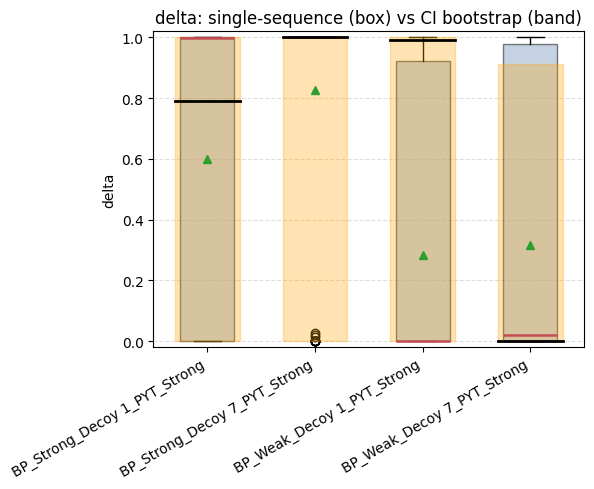

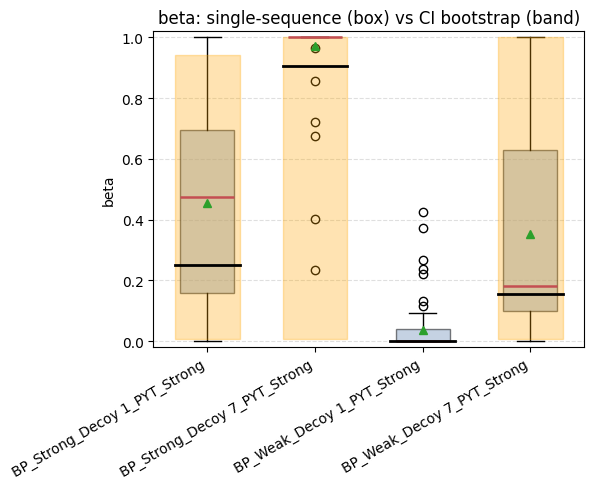

In [31]:
# shared_full = fixed_params (k1, k2) + shared best_dict (k_1, k_2, k3, k4, alpha)
shared_full_pb = {**fixed_params, **{k: best_dict_pb[k] for k in shared_param_names}}

seq_dist_pb = fit.fit_class_sequence_distribution(
    classes_data           = classes_data,
    class_names              = class_names,
    drug_conc                 = DRUG_CONCENTRATIONS,
    model_name                  = model_4,
    shared_params                 = shared_full_pb,
    n_sequences_per_class            = 80,
    n_starts                          = 10,
    random_state                       = 0,
)


def plot_sequence_vs_class_ci(seq_dist, df_boot, class_names, scaler='delta', only_successful=True):
    """Boxplot single-sequence (within-class) sovrapposto alla banda del CI bootstrap di classe."""
    data_boot = df_boot[df_boot['success']] if only_successful else df_boot
    fig, ax = plt.subplots(figsize=(max(6, len(class_names) * 1.4), 5))

    box_data = [seq_dist.loc[seq_dist['class'] == c, scaler].dropna().values for c in class_names]
    bp = ax.boxplot(box_data, positions=np.arange(len(class_names)), widths=0.5,
                     patch_artist=True, showmeans=True,
                     medianprops=dict(color='#C44E52', linewidth=1.8))
    for patch in bp['boxes']:
        patch.set_facecolor('#8CA6C9')
        patch.set_alpha(0.5)

    for i, c in enumerate(class_names):
        ci_lo, ci_hi = data_boot[f'{scaler}_{c}'].quantile([0.025, 0.975])
        ci_med = data_boot[f'{scaler}_{c}'].median()
        ax.plot([i - 0.3, i + 0.3], [ci_med, ci_med], color='black', lw=2, zorder=4)
        ax.fill_between([i - 0.3, i + 0.3], ci_lo, ci_hi, color='orange', alpha=0.3, zorder=2)

    ax.set_xticks(np.arange(len(class_names)))
    ax.set_xticklabels(class_names, rotation=30, ha='right')
    ax.set_ylabel(scaler)
    ax.set_ylim(-0.02, 1.02)
    ax.set_title(f'{scaler}: single-sequence (box) vs CI bootstrap (band)')
    ax.grid(True, axis='y', linestyle='--', alpha=0.4)
    plt.tight_layout()
    plt.show()


plot_sequence_vs_class_ci(seq_dist_pb, df_boot_pb, class_names, scaler='delta')
plot_sequence_vs_class_ci(seq_dist_pb, df_boot_pb, class_names, scaler='beta')

# Capitolo 4.4 — Correlazione tra parametri condivisi (identificabilità)

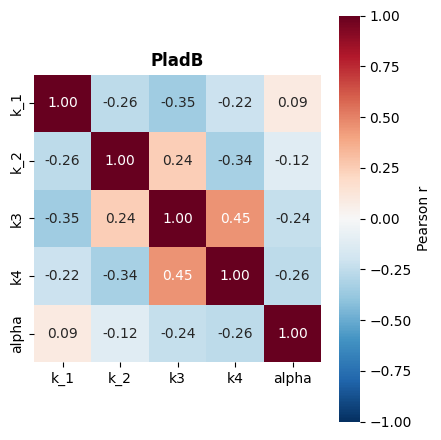

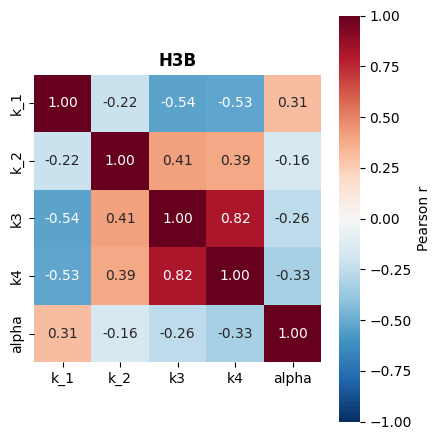

In [32]:
def plot_bootstrap_param_correlation(df_boot, shared_param_names, only_successful=True,
                                       title='Correlazione tra parametri condivisi (repliche bootstrap)'):
    data = df_boot[df_boot['success']] if only_successful else df_boot
    corr = data[shared_param_names].corr()

    fig, ax = plt.subplots(figsize=(1 + 0.7 * len(shared_param_names), 1 + 0.7 * len(shared_param_names)))
    sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1,
                square=True, cbar_kws={'label': 'Pearson r'}, ax=ax)
    ax.set_title(title, fontweight='bold')
    plt.tight_layout()
    plt.show()
    return corr

corr_pb  = plot_bootstrap_param_correlation(df_boot_pb, shared_param_names, title='PladB')
corr_h3b = plot_bootstrap_param_correlation(df_boot_h3b, shared_param_names, title='H3B')